# Lyric category prediction — TF-IDF baseline

**Lyrics → existing tokenizer → TF-IDF (unigrams + bigrams) → one-vs-rest logistic regression.**

This first CPU model uses `TfidfVectorizer(ngram_range=(1, 2))` and `OneVsRestClassifier(LogisticRegression(max_iter=1000))`. All labeled songs are used. The vocabulary remains limited to 20,000 features for CPU memory use. The current dataset has **one genre per song**, so this run predicts one category. The classifier also accepts genuine multilabel targets later.

Run the notebook in the course environment with the packages in `requirements.txt`.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'model.py').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'model.py').exists():
    raise FileNotFoundError('Open this notebook from the project root or notebooks folder.')
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay

from model import build_model, evaluate_model, split_lyrics_data
from utils import load_prediction_data

## Load the existing preprocessing outputs

The loader first checks `data/processed/`, then the `normalized_x_*.csv` exports from `preprocessing.ipynb`. Those training exports omit `tag`, so labels are joined by `id`. If no exports exist, it applies the existing `text_quality.normalize_lyrics` to raw lyrics. Saved API metadata corrections are unavailable in that case; only lyrics enter this model.

Model tokenization removes bracketed annotations, lowercases words, preserves accents and contractions, and keeps stopwords. It needs no NLTK downloads. Padding is unnecessary for TF-IDF.

In [2]:
RANDOM_STATE = 39

train_data, test_data = load_prediction_data(PROJECT_ROOT / 'data')
usable = train_data['lyrics'].fillna('').str.strip().ne('')
print(f'Excluding {(~usable).sum():,} empty training lyrics.')
train_data = train_data.loc[usable].copy()
print(f'Train: {len(train_data):,} | Official test: {len(test_data):,}')
display(train_data['tag'].value_counts().rename('songs').to_frame())

No saved preprocessing outputs found; normalizing raw lyrics. Saved metadata corrections are unavailable; the model uses lyrics only.
Excluding 0 empty training lyrics.
Train: 134,967 | Official test: 33,742


,songs
tag,
pop,55742
rap,38584
rock,25332
rb,6203
misc,5640
country,3466


## Split before fitting TF-IDF

Use the complete labeled dataset. A grouped split keeps identical final token sequences together, preventing duplicate lyrics from crossing training and validation. Five stratified group folds give approximately 80/20 with the professor's seed, 39.

The vocabulary, IDF weights, and classifier learn only from training lyrics. Use a separate tuning split if you later compare models; this held-out set is for assessing this fixed baseline.

After this evaluation, a fresh final model is fitted on every labeled song for official test predictions.

In [3]:
fit_data, validation_data = split_lyrics_data(train_data, RANDOM_STATE)
print(f'Fit: {len(fit_data):,} | Validation: {len(validation_data):,}')
display(pd.concat([
    fit_data['tag'].value_counts().rename('fit'),
    validation_data['tag'].value_counts().rename('validation'),
], axis=1).fillna(0).astype(int))

Fit: 107,973 | Validation: 26,994


,fit,validation
tag,,
pop,44593,11149
rap,30867,7717
rock,20266,5066
rb,4962,1241
misc,4512,1128
country,2773,693


In [4]:
print(f'Training the evaluation model on {len(fit_data):,} songs.')
model = build_model(random_state=RANDOM_STATE)
model.fit(fit_data['lyrics'], fit_data['tag'])

vectorizer = model.named_steps['tfidf']
print(f'TF-IDF features: {len(vectorizer.vocabulary_):,}')

Training the evaluation model on 107,973 songs.
TF-IDF features: 20,000


## Evaluate using the TM06 classification metrics

Report accuracy, weighted precision/recall/F1 (`zero_division=0`), macro/micro F1, and support-weighted ROC AUC from continuous probabilities. AUC is undefined for a category with no positive or no negative validation examples; such categories are reported and omitted from the AUC average.

For genuine multilabel targets, accuracy becomes exact label-set accuracy and predictions use an independent probability threshold of 0.5. For this single-label dataset, each prediction selects one genre.

In [5]:
evaluation = evaluate_model(model, validation_data['lyrics'], validation_data['tag'])
display(evaluation['metrics'].round(4).to_frame())
display(evaluation['classification_report'].round(4))
display(evaluation['roc_auc_by_class'].round(4))
print('Undefined AUC categories:', evaluation['auc_undefined_labels'])

Undefined AUC categories: []


,validation
accuracy,0.6660
precision_weighted,0.6560
recall_weighted,0.6660
f1_weighted,0.6274
f1_macro,0.4420
f1_micro,0.6660
roc_auc_weighted,0.8477


,precision,recall,f1-score,support
country,0.4694,0.0332,0.0620,693.000
misc,0.8439,0.4938,0.6230,1128.000
pop,0.5937,0.8503,0.6992,11149.000
rap,0.8543,0.8534,0.8539,7717.000
rb,0.5100,0.0411,0.0761,1241.000
rock,0.5104,0.2527,0.3380,5066.000
accuracy,0.6660,0.6660,0.6660,0.666
macro avg,0.6303,0.4207,0.4420,26994.000
weighted avg,0.6560,0.6660,0.6274,26994.000


,roc_auc,support
country,0.8815,693
misc,0.8946,1128
pop,0.7859,11149
rap,0.9600,7717
rb,0.8311,1241
rock,0.8014,5066


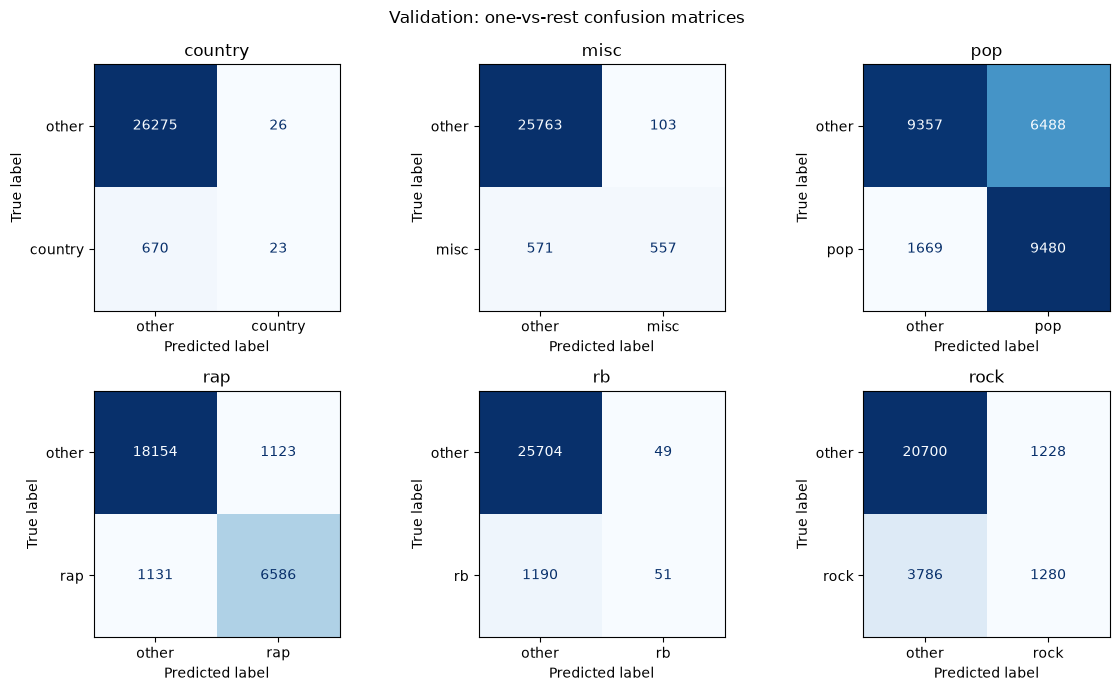

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, category, matrix in zip(
    axes.flat, model.classes_, evaluation['confusion_matrices']
):
    ConfusionMatrixDisplay(matrix, display_labels=['other', category]).plot(
        ax=ax, colorbar=False, cmap='Blues', values_format='d',
    )
    ax.set_title(category)
plt.suptitle('Validation: one-vs-rest confusion matrices')
plt.tight_layout()
plt.show()

In [7]:
examples = validation_data[['id', 'title', 'tag']].copy()
examples['predicted_tag'] = evaluation['predictions']
display(examples.head(10))

,id,title,tag,predicted_tag
3,1584150,Stealing Hearts,pop,pop
11,6523416,Alameda,pop,pop
15,1007749,Enjoy the Silence,pop,pop
18,7268319,Resale,rock,pop
21,1449137,Cauterize,rock,pop
22,3331151,Wildchild,pop,pop
23,1857471,Mr. Face,pop,pop
24,1095455,If You’re Ever In My Arms,country,pop
25,7138222,24 More Days,pop,rap
26,1501840,The Way We Were,rock,pop


## Predict the official test lyrics

The official test has no known labels. `sample_submission.csv` is an output template, never evaluation ground truth; its row order differs from `test.csv`. Match predictions by `id`.

The validation metrics above belong to the held-out split. Now fit a fresh model on **all labeled songs** and use it for the official test predictions. Validation rows enter this final fit only after evaluation is complete.

In [8]:
print(f'Training the final model on all {len(train_data):,} labeled songs.')
final_model = build_model(random_state=RANDOM_STATE)
final_model.fit(train_data['lyrics'], train_data['tag'])
print(f'Final model fitted on all {len(train_data):,} labeled songs.')

test_predictions = pd.DataFrame({
    'id': test_data['id'],
    'tag': final_model.predict(test_data['lyrics'].fillna('')),
})
submission = pd.read_csv(PROJECT_ROOT / 'data' / 'sample_submission.csv')
assert submission['id'].is_unique and len(submission) == len(test_predictions)
if set(submission['id']) != set(test_predictions['id']):
    raise ValueError('Submission template and test data have different song IDs.')
submission['tag'] = submission['id'].map(test_predictions.set_index('id')['tag'])
assert submission['tag'].notna().all()

output_path = PROJECT_ROOT / 'data' / 'processed' / 'submission_tfidf.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(output_path, index=False)
print(f'Saved {len(submission):,} predictions to {output_path}')
display(submission.head())

Training the final model on all 134,967 labeled songs.
Final model fitted on all 134,967 labeled songs.
Saved 33,742 predictions to /Users/cicerosantos/Documents/GitHub/Text-Mining-/data/processed/submission_tfidf.csv


,id,tag
0,3230388,pop
1,3658643,pop
2,1270714,pop
3,3354312,rap
4,493974,pop


## Later: actual multilabel annotations and embeddings

When each song has a real list of categories, encode those lists with `MultiLabelBinarizer`, pass its indicator matrix to `build_model().fit(...)`, and decode predictions with `inverse_transform`. Pass `label_names=encoder.classes_` to `evaluate_model` to preserve category order. The classifier then makes independent 0.5-threshold decisions and can predict several genres per song. The current tags do not provide such annotations.

`build_word2vec_model()` remains available for the original TM05 comparison: existing tokens → small Word2Vec → mean lyric vectors → logistic regression. TF-IDF is the default first model.

Metrics follow TM06, cells 65–81. API details: [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), [OneVsRestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html).